# Лабораторная работа №4: Байесовская сеть

**Цель работы:** научиться представлять зависимости между случайными величинами с помощью байесовской сети, самостоятельно строить структуру ориентированного ациклического графа (DAG), оценивать таблицы условных вероятностей (CPD) и выполнять вероятностный вывод при наличии дополнительной информации (`evidence`).

---

## 1. Выбор и описание данных

Для работы выбран открытый датасет **UCI Student Performance Dataset** (`student-mat.csv`, репозиторий UCI Machine Learning Repository: <https://archive.ics.uci.edu/dataset/320/student+performance>).

### Описание предметной области и переменных
- **Что представляет собой один объект:** один учащийся старшей школы (курс математики, 395 наблюдений), описанный социально-демографическими, поведенческими и учебными признаками.
- **Выбранные для построения байесовской сети переменные (6 узлов):**
  1. `Medu` (*Mother's education*) — уровень образования матери (от `0` — нет до `4` — высшее образование). Отражает образовательный и культурный капитал семьи.
  2. `higher` (*Wants to take higher education*) — планирует ли ученик поступать в вуз (`yes` / `no`). Отражает академическую мотивацию.
  3. `goout` (*Going out with friends*) — как часто ученик проводит время на прогулках/в компаниях с друзьями (шкала от `1` — очень редко до `5` — очень часто).
  4. `studytime` (*Weekly study time*) — еженедельное время самостоятельной учёбы (`1`: <2 ч, `2`: 2–5 ч, `3`: 5–10 ч, `4`: >10 ч).
  5. `absences` (*Number of school absences*) — количество пропущенных занятий за учебный период (непрерывный целочисленный признак от `0` до `93`).
  6. `failures` (*Past class failures*) — количество прошлых академических задолженностей/пересдач (`0`, `1`, `2`, `3`).
  7. `G3` (*Final grade*) — итоговая оценка за курс по 20-балльной шкале (от `0` до `20`, где порог сдачи `G3 >= 10`).

### Предполагаемые содержательные зависимости
- Образовательный уровень семьи (`Medu`) повышает вероятность того, что школьник нацелен на получение высшего образования (`higher`).
- Стремление поступить в вуз (`higher`) и частота прогулок с друзьями (`goout`) напрямую влияют на то, сколько времени школьник уделяет самоподготовке (`studytime`).
- Частое времяпрепровождение в компаниях (`goout`) и низкая мотивация к учёбе (`higher`) увеличивают число прогулов занятий (`absences`).
- Малое время самоподготовки (`studytime`) и прогулы (`absences`) повышают риск накопления академических задолженностей (`failures`).
- Наконец, регулярность занятий (`studytime`), посещаемость (`absences`) и наличие прошлых «хвостов» (`failures`) определяют итоговую успеваемость по предмету (`G3`).

In [1]:
import io
import os
import zipfile
import urllib.request
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

In [2]:
def load_student_dataset() -> pd.DataFrame:
    """Загружает датасет UCI Student Performance (локально, из архива UCI или зеркала GitHub)."""
    local_candidates = ["student-mat.csv", "student-por.csv"]
    for path in local_candidates:
        if os.path.exists(path):
            sep = ";" if ";" in open(path, encoding="utf-8").readline() else ","
            print(f"Загружен локальный файл: {path}")
            return pd.read_csv(path, sep=sep)

    # 1. Официальный архив UCI Machine Learning Repository
    uci_zip_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"
    try:
        with urllib.request.urlopen(uci_zip_url, timeout=15) as resp:
            with zipfile.ZipFile(io.BytesIO(resp.read())) as zf:
                with zf.open("student-mat.csv") as f:
                    df_loaded = pd.read_csv(f, sep=";")
                    df_loaded.to_csv("student-mat.csv", index=False)
                    print("Датасет успешно загружен из официального репозитория UCI и сохранён в student-mat.csv")
                    return df_loaded
    except Exception as e:
        print(f"Не удалось скачать ZIP из UCI ({e}), пробуем зеркало GitHub...")

    # 2. Прямое зеркало CSV на GitHub
    github_url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/04_Apply/Students_Alcohol_Consumption/student-mat.csv"
    df_loaded = pd.read_csv(github_url)
    df_loaded.to_csv("student-mat.csv", index=False)
    print("Датасет загружен с зеркала GitHub и сохранён в student-mat.csv")
    return df_loaded


raw_df = load_student_dataset()
selected_cols = ["Medu", "higher", "goout", "studytime", "absences", "failures", "G3"]
df_sub = raw_df[selected_cols].copy()

print(f"Размерность таблицы: {df_sub.shape}")
display(df_sub.head())

Датасет успешно загружен из официального репозитория UCI и сохранён в student-mat.csv
Размерность таблицы: (395, 7)


,Medu,higher,goout,studytime,absences,failures,G3
0,4,yes,4,2,6,0,6
1,1,yes,3,2,4,0,6
2,1,yes,2,2,10,3,10
3,4,yes,2,3,2,0,15
4,3,yes,2,2,4,0,10


## 2. Первичный анализ и подготовка данных (дискретизация)

Проверим выбранные признаки на:
- **пропущенные значения**,
- **редкие категории**,
- **количество возможных состояний**,
- **достаточность числа наблюдений** для оценки таблиц условных вероятностей (CPD).

В дискретной байесовской сети размер таблицы условных вероятностей узла $X$ с родителями $Pa(X)$ равен произведению мощностей их алфавитов: $|Val(X)| \times \prod_{U \in Pa(X)} |Val(U)|$.  
При объёме выборки $N = 395$ слишком дробное разбиение (например, 5–10 категорий на признак) приведёт к тому, что во многих комбинациях родителей окажется 0 или 1 наблюдение. Поэтому преобразуем переменные в **компактные содержательные категории (по 2–3 состояния)**:

1. **`ParentEdu`** (из `Medu`):
   - `Low_Mid` (`Medu <= 2`: нет образования, начальное или среднее до 9 классов),
   - `High` (`Medu >= 3`: полное среднее или высшее образование).  
   *Обоснование:* категория `Medu = 0` встречается всего 3 раза (редкая категория), поэтому объединение в два содержательных уровня устраняет разреженность.
2. **`HigherGoal`** (из `higher`):
   - `No` (`higher == 'no'`),
   - `Yes` (`higher == 'yes'`).
3. **`SocialOut`** (из `goout`):
   - `Low_Mod` (`goout <= 3` — редкие или умеренные прогулки с друзьями),
   - `High` (`goout >= 4` — частые/очень частые компании и тусовки).
4. **`StudyTime`** (из `studytime`):
   - `Short` (`studytime == 1`: менее 2 часов в неделю),
   - `Medium` (`studytime == 2`: от 2 до 5 часов в неделю),
   - `Long` (`studytime >= 3`: более 5 часов в неделю; объединяем редкую категорию `4` с `3`).
5. **`Absences`** (дискретизация непрерывного признака `absences`):
   - `Low` (`0–2` пропуска — единичные отсутствия),
   - `Medium` (`3–7` пропусков — умеренные пропуски),
   - `High` (`>= 8` пропусков — систематические прогулы).  
   *Обоснование:* распределение `absences` сильно скошено вправо (медиана = 4, но есть хвост до 75), поэтому пороги выбраны по квантилям и смыслу школьной посещаемости, чтобы сбалансировать наполненность групп.
6. **`PastFailures`** (из `failures`):
   - `None` (`failures == 0` — не было задолженностей),
   - `HasFailures` (`failures >= 1` — была хотя бы одна пересдача; значения `2` и `3` редки, поэтому объединяются).
7. **`FinalGrade`** (дискретизация целевого признака `G3`):
   - `Fail` (`G3 < 10` — неудовлетворительно, курс не сдан по португальской 20-балльной шкале),
   - `Pass` (`10 <= G3 <= 13` — базовый проходной балл),
   - `Good` (`G3 >= 14` — хорошая и отличная успеваемость).

In [3]:
print("Пропущенные значения по столбцам:")
print(df_sub.isnull().sum())

print("\nЧастоты исходных категориальных/порядковых признаков:")
for col in ["Medu", "higher", "goout", "studytime", "failures"]:
    print(f"--- {col} ---")
    print(df_sub[col].value_counts().sort_index())

print("\nОписательная статистика непрерывных признаков (absences, G3):")
display(df_sub[["absences", "G3"]].describe())

Пропущенные значения по столбцам:
Medu         0
higher       0
goout        0
studytime    0
absences     0
failures     0
G3           0
dtype: int64

Частоты исходных категориальных/порядковых признаков:
--- Medu ---
Medu
0      3
1     59
2    103
3     99
4    131
Name: count, dtype: int64
--- higher ---
higher
no      20
yes    375
Name: count, dtype: int64
--- goout ---
goout
1     23
2    103
3    130
4     86
5     53
Name: count, dtype: int64
--- studytime ---
studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64
--- failures ---
failures
0    312
1     50
2     17
3     16
Name: count, dtype: int64

Описательная статистика непрерывных признаков (absences, G3):


,absences,G3
count,395.000000,395.000000
mean,5.708861,10.415190
std,8.003096,4.581443
min,0.000000,0.000000
25%,0.000000,8.000000
50%,4.000000,11.000000
75%,8.000000,14.000000
max,75.000000,20.000000


In [4]:
# Дискретизация признаков и объединение редких категорий
bn_df = pd.DataFrame(index=df_sub.index)

bn_df["ParentEdu"] = np.where(df_sub["Medu"] >= 3, "High", "Low_Mid")
bn_df["HigherGoal"] = np.where(df_sub["higher"] == "yes", "Yes", "No")
bn_df["SocialOut"] = np.where(df_sub["goout"] >= 4, "High", "Low_Mod")

bn_df["StudyTime"] = pd.cut(
    df_sub["studytime"],
    bins=[0, 1, 2, 10],
    labels=["Short", "Medium", "Long"],
).astype(str)

bn_df["Absences"] = pd.cut(
    df_sub["absences"],
    bins=[-1, 2, 7, 1000],
    labels=["Low", "Medium", "High"],
).astype(str)

bn_df["PastFailures"] = np.where(df_sub["failures"] == 0, "None", "HasFailures")

bn_df["FinalGrade"] = pd.cut(
    df_sub["G3"],
    bins=[-1, 9, 13, 20],
    labels=["Fail", "Pass", "Good"],
).astype(str)

# Упорядочим состояния для наглядного отображения в таблицах
STATE_ORDER = {
    "ParentEdu": ["Low_Mid", "High"],
    "HigherGoal": ["No", "Yes"],
    "SocialOut": ["Low_Mod", "High"],
    "StudyTime": ["Short", "Medium", "Long"],
    "Absences": ["Low", "Medium", "High"],
    "PastFailures": ["None", "HasFailures"],
    "FinalGrade": ["Fail", "Pass", "Good"],
}

print("Распределение состояний после дискретизации (N = 395):")
for col, states in STATE_ORDER.items():
    counts = bn_df[col].value_counts().reindex(states, fill_value=0)
    perc = (counts / len(bn_df) * 100).round(1)
    summary = ", ".join([f"{s}: {counts[s]} ({perc[s]}%)" for s in states])
    print(f"  {col:13s} ({len(states)} сост.) -> {summary}")

Распределение состояний после дискретизации (N = 395):
  ParentEdu     (2 сост.) -> Low_Mid: 165 (41.8%), High: 230 (58.2%)
  HigherGoal    (2 сост.) -> No: 20 (5.1%), Yes: 375 (94.9%)
  SocialOut     (2 сост.) -> Low_Mod: 256 (64.8%), High: 139 (35.2%)
  StudyTime     (3 сост.) -> Short: 105 (26.6%), Medium: 198 (50.1%), Long: 92 (23.3%)
  Absences      (3 сост.) -> Low: 183 (46.3%), Medium: 104 (26.3%), High: 108 (27.3%)
  PastFailures  (2 сост.) -> None: 312 (79.0%), HasFailures: 83 (21.0%)
  FinalGrade    (3 сост.) -> Fail: 130 (32.9%), Pass: 165 (41.8%), Good: 100 (25.3%)


## 3. Постановка вероятностных вопросов (до построения сети)

Сформулируем **4 содержательных вопроса** к нашей вероятностной модели:

1. **Запрос 1 (влияние мотивации и времени учёбы на оценку):**  
   Как изменится распределение итоговой успеваемости `P(FinalGrade)` по сравнению с априорным, если известно, что ученик занимается много (`StudyTime = Long`) и не имел прошлых задолженностей (`PastFailures = None`)?
2. **Запрос 2 (комбинация факторов риска):**  
   Какова вероятность завалить предмет `P(FinalGrade = Fail | SocialOut = High, Absences = High)` для ученика, который часто гуляет с друзьями и много пропускает занятия, по сравнению с безусловной вероятностью `P(FinalGrade = Fail)`?
3. **Запрос 3 (диагностический вывод «снизу вверх» — от следствия к причине):**  
   Как изменится апостериорная вероятность того, что у ученика были прошлые задолженности `P(PastFailures = HasFailures | FinalGrade = Fail)` и что он мало учился `P(StudyTime = Short | FinalGrade = Fail)`, если нам стало известно, что он не сдал итоговый экзамен (`FinalGrade = Fail`)?
4. **Запрос 4 (влияние семьи через промежуточные вершины):**  
   Насколько знание об уровне образования родителей `ParentEdu = High` повышает вероятность выбора вуза `P(HigherGoal = Yes | ParentEdu = High)` и высокой итоговой оценки `P(FinalGrade = Good | ParentEdu = High)`?

## 4. Построение структуры байесовской сети (DAG)

Предложим следующую ориентированную ациклическую структуру (8 направленных рёбер между 7 вершинами):

1. `ParentEdu -> HigherGoal`  
   *Обоснование зависимости и направления:* образование родителей формируется задолго до учёбы ребёнка в школе (временной приоритет) и влияет на академические амбиции семьи и желание школьника поступать в вуз, а не наоборот.
2. `ParentEdu -> StudyTime`  
   *Обоснование:* в семьях с высшим образованием родители чаще контролируют выполнение домашних заданий и организуют учебный режим.
3. `HigherGoal -> StudyTime`  
   *Обоснование:* цель поступить в университет мотивирует старшеклассника выделять больше часов в неделю на самоподготовку.
4. `SocialOut -> StudyTime`  
   *Обоснование:* частые прогулки с друзьями конкурируют за бюджет свободного времени школьника, сокращая время на учёбу.
5. `SocialOut -> Absences`  
   *Обоснование:* активная тусовочная жизнь повышает склонность пропускать утренние уроки.
6. `StudyTime -> PastFailures`  
   *Обоснование:* недостаток регулярной подготовки приводит к накоплению академических задолженностей.
7. `Absences -> FinalGrade`, `StudyTime -> FinalGrade`, `PastFailures -> FinalGrade`  
   *Обоснование:* итоговая оценка за курс формируется в конце года как результат глубины освоения материала (`StudyTime`), посещаемости уроков (`Absences`) и наличия/отсутствия пробелов в базе (`PastFailures`).

In [5]:
# Задаём рёбра ориентированного ациклического графа (DAG)
DAG_EDGES = [
    ("ParentEdu", "HigherGoal"),
    ("ParentEdu", "StudyTime"),
    ("HigherGoal", "StudyTime"),
    ("SocialOut", "StudyTime"),
    ("SocialOut", "Absences"),
    ("StudyTime", "PastFailures"),
    ("StudyTime", "FinalGrade"),
    ("Absences", "FinalGrade"),
    ("PastFailures", "FinalGrade"),
]


def verify_dag(nodes, edges):
    """Проверка графа на отсутствие ориентированных циклов (топологическая сортировка Кана)."""
    in_degree = {u: 0 for u in nodes}
    adj = {u: [] for u in nodes}
    for u, v in edges:
        adj[u].append(v)
        in_degree[v] += 1

    queue = [u for u, deg in in_degree.items() if deg == 0]
    topo_order = []
    while queue:
        curr = queue.pop(0)
        topo_order.append(curr)
        for nxt in adj[curr]:
            in_degree[nxt] -= 1
            if in_degree[nxt] == 0:
                queue.append(nxt)

    is_acyclic = len(topo_order) == len(nodes)
    return is_acyclic, topo_order


is_dag, topo_nodes = verify_dag(list(STATE_ORDER.keys()), DAG_EDGES)
print(f"Граф является корректным DAG (без циклов): {is_dag}")
print("Топологический порядок вершин:", " -> ".join(topo_nodes))

Граф является корректным DAG (без циклов): True
Топологический порядок вершин: ParentEdu -> SocialOut -> HigherGoal -> Absences -> StudyTime -> PastFailures -> FinalGrade


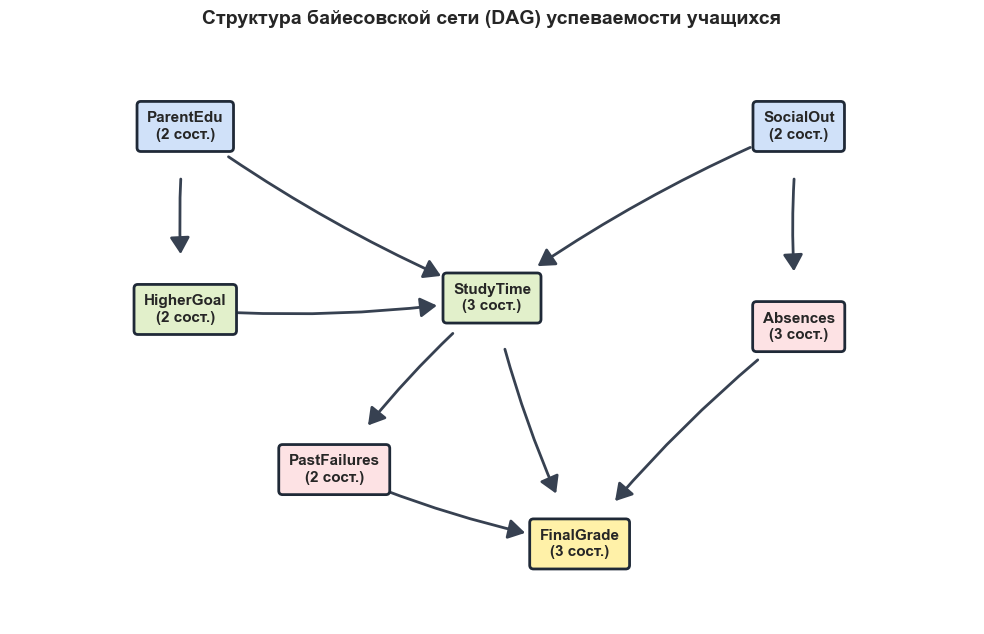

In [6]:
# Визуализация ориентированного графа байесовской сети
def plot_bayesian_network(edges, title="Структура байесовской сети (DAG) успеваемости учащихся"):
    pos = {
        "ParentEdu": (0.15, 0.85),
        "SocialOut": (0.85, 0.85),
        "HigherGoal": (0.15, 0.53),
        "StudyTime": (0.50, 0.55),
        "Absences": (0.85, 0.50),
        "PastFailures": (0.32, 0.25),
        "FinalGrade": (0.60, 0.12),
    }

    node_colors = {
        "ParentEdu": "#d0e1f9",
        "SocialOut": "#d0e1f9",
        "HigherGoal": "#e2f0cb",
        "StudyTime": "#e2f0cb",
        "Absences": "#fde2e4",
        "PastFailures": "#fde2e4",
        "FinalGrade": "#fff1a8",
    }

    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.02, 1.00)
    ax.axis("off")

    # Отрисовка направленных рёбер
    for u, v in edges:
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            connectionstyle="arc3,rad=0.06",
            arrowstyle="-|>,head_length=10,head_width=6",
            color="#374151",
            lw=2.0,
            shrinkA=38,
            shrinkB=40,
            zorder=2,
        )
        ax.add_patch(arrow)

    # Отрисовка вершин
    for node, (x, y) in pos.items():
        bbox_props = dict(
            boxstyle="round,pad=0.65,rounding_size=0.25",
            facecolor=node_colors.get(node, "#e5e7eb"),
            edgecolor="#1f2937",
            linewidth=2.0,
        )
        ax.text(
            x,
            y,
            f"{node}\n({len(STATE_ORDER[node])} сост.)",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            bbox=bbox_props,
            zorder=3,
        )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    plt.tight_layout()
    plt.show()


plot_bayesian_network(DAG_EDGES)

## 5. Оценка параметров сети (таблицы условных вероятностей CPD)

Оценим условные вероятности $P(X \mid Pa(X))$ по данным методом максимального правдоподобия со слабым сглаживанием Лапласа ($\alpha = 0.5$), чтобы избежать нулевых вероятностей в редких сочетаниях родителей.

Ниже реализован универсальный класс `DiscreteBayesianNetwork`, который:
1. Поддерживает как `pgmpy` (если библиотека установлена в окружении), так и встроенный точный табличный алгоритм **Variable Elimination / Полная факторизация совместного распределения** $$P(X_1, \dots, X_n) = \prod_{i=1}^n P(X_i \mid Pa(X_i))$$ на чистом `pandas`/`numpy`.
2. Позволяет наглядно выводить таблицы условных вероятностей (CPD) и выполнять любые условные запросы $P(Q \mid E = e)$.

In [7]:
class DiscreteBayesianNetwork:
    """Компактная реализация дискретной байесовской сети с точным вероятностным выводом."""

    def __init__(self, state_order: dict, edges: list, laplace_alpha: float = 0.5):
        self.state_order = state_order
        self.nodes = list(state_order.keys())
        self.edges = list(edges)
        self.alpha = laplace_alpha
        self.parents = {n: [] for n in self.nodes}
        for u, v in self.edges:
            self.parents[v].append(u)
        self.cpds = {}
        self.joint_df = None

    def fit(self, df: pd.DataFrame):
        """Оценивает таблицы условных вероятностей P(X | Pa(X)) по датасету."""
        self.cpds = {}
        for node in self.nodes:
            states = self.state_order[node]
            pars = self.parents[node]

            if not pars:
                counts = df[node].value_counts().reindex(states, fill_value=0) + self.alpha
                probs = counts / counts.sum()
                cpd_df = pd.DataFrame(probs.values.reshape(-1, 1), index=states, columns=["P(" + node + ")"])
                self.cpds[node] = cpd_df
            else:
                par_states = [self.state_order[p] for p in pars]
                col_index = pd.MultiIndex.from_product(par_states, names=pars)
                cpd_df = pd.DataFrame(0.0, index=states, columns=col_index)

                grouped = df.groupby(pars + [node]).size()
                for comb in col_index:
                    comb_tuple = comb if isinstance(comb, tuple) else (comb,)
                    sub_counts = []
                    for s in states:
                        key = comb_tuple + (s,) if len(pars) > 1 else (comb_tuple[0], s)
                        sub_counts.append(grouped.get(key, 0.0) + self.alpha)
                    sub_counts = np.array(sub_counts, dtype=float)
                    cpd_df[comb] = sub_counts / sub_counts.sum()

                self.cpds[node] = cpd_df

        self._build_joint_distribution()
        return self

    def _build_joint_distribution(self):
        """Строит полное совместное распределение по цепному правилу байесовской сети."""
        all_states = [self.state_order[n] for n in self.nodes]
        rows = []
        for assignment in product(*all_states):
            state_map = dict(zip(self.nodes, assignment))
            p_val = 1.0
            for node in self.nodes:
                pars = self.parents[node]
                cpd = self.cpds[node]
                if not pars:
                    p_val *= float(cpd.loc[state_map[node]].iloc[0])
                elif len(pars) == 1:
                    p_val *= float(cpd.loc[state_map[node], state_map[pars[0]]])
                else:
                    par_key = tuple(state_map[p] for p in pars)
                    p_val *= float(cpd.loc[state_map[node], par_key])
            rows.append((*assignment, p_val))

        self.joint_df = pd.DataFrame(rows, columns=self.nodes + ["prob"])

    def query(self, target: str, evidence: dict = None) -> pd.Series:
        """Точный вероятностный вывод P(target | evidence)."""
        sub = self.joint_df
        if evidence:
            for k, v in evidence.items():
                sub = sub[sub[k] == v]
        marg = sub.groupby(target)["prob"].sum().reindex(self.state_order[target], fill_value=0.0)
        return marg / marg.sum()


bn = DiscreteBayesianNetwork(STATE_ORDER, DAG_EDGES, laplace_alpha=0.5).fit(bn_df)
print(f"Сеть обучена! Размерность пространства элементарных исходов: {len(bn.joint_df)} комбинаций.")
print(f"Проверка нормировки совместного распределения: сумма вероятностей = {bn.joint_df['prob'].sum():.6f}")

C:\Users\pomak\AppData\Local\Temp\ipykernel_5048\3329256040.py:60: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  p_val *= float(cpd.loc[state_map[node], state_map[pars[0]]])


Сеть обучена! Размерность пространства элементарных исходов: 432 комбинаций.
Проверка нормировки совместного распределения: сумма вероятностей = 1.000000


In [8]:
# Выведем и проанализируем таблицы условных вероятностей (CPD) для ключевых узлов
print("1. CPD узла HigherGoal P(HigherGoal | ParentEdu):")
display(bn.cpds["HigherGoal"].round(4))

print("\n2. CPD узла Absences P(Absences | SocialOut):")
display(bn.cpds["Absences"].round(4))

print("\n3. CPD узла StudyTime P(StudyTime | ParentEdu, HigherGoal, SocialOut):")
display(bn.cpds["StudyTime"].round(4))

print("\n4. CPD целевого узла FinalGrade P(FinalGrade | StudyTime, Absences, PastFailures) — срез для PastFailures = None и HasFailures:")
display(bn.cpds["FinalGrade"].round(4))

1. CPD узла HigherGoal P(HigherGoal | ParentEdu):


ParentEdu,Low_Mid,High
No,0.0873,0.0281
Yes,0.9127,0.9719



2. CPD узла Absences P(Absences | SocialOut):


SocialOut,Low_Mod,High
Low,0.4990,0.3950
Medium,0.2505,0.2883
High,0.2505,0.3167



3. CPD узла StudyTime P(StudyTime | ParentEdu, HigherGoal, SocialOut):


ParentEdu  Low_Mid                            High                        
HigherGoal      No             Yes              No             Yes        
SocialOut  Low_Mod    High Low_Mod    High Low_Mod    High Low_Mod    High
Short       0.5789  0.3333  0.2850  0.2475  0.5556  0.7778  0.2042  0.2848
Medium      0.3684  0.6000  0.4686  0.5446  0.3333  0.1111  0.4671  0.5879
Long        0.0526  0.0667  0.2464  0.2079  0.1111  0.1111  0.3287  0.1273


4. CPD целевого узла FinalGrade P(FinalGrade | StudyTime, Absences, PastFailures) — срез для PastFailures = None и HasFailures:


StudyTime      Short                                                      \
Absences         Low              Medium                High               
PastFailures    None HasFailures    None HasFailures    None HasFailures   
Fail          0.1746      0.8065  0.1765      0.5294  0.3023      0.5652   
Pass          0.4921      0.1613  0.3725      0.2941  0.5814      0.3043   
Good          0.3333      0.0323  0.4510      0.1765  0.1163      0.1304   

StudyTime     Medium                                                      \
Absences         Low              Medium                High               
PastFailures    None HasFailures    None HasFailures    None HasFailures   
Fail          0.2335      0.7419  0.2958      0.5294  0.3563      0.5610   
Pass          0.4251      0.2258  0.6056      0.4118  0.4483      0.4146   
Good          0.3413      0.0323  0.0986      0.0588  0.1954      0.0244   

StudyTime       Long                                                      
Absences         Low              Medium                High              
PastFailures    None HasFailures    None HasFailures    None HasFailures  
Fail          0.3165      0.5385  0.1429      0.1429  0.2593      0.2308  
Pass          0.2658      0.3846  0.3651      0.4286  0.4074      0.6923  
Good          0.4177      0.0769  0.4921      0.4286  0.3333      0.0769

### Анализ полученных таблиц условных вероятностей (CPD)
1. **`P(HigherGoal | ParentEdu)`:**  
   У школьников из семей с высоким уровнем образования (`ParentEdu = High`) вероятность стремления в вуз составляет **~97–98%**, тогда как при `ParentEdu = Low_Mid` доля не планирующих идти в вуз (`No`) заметно выше (~8–9%). Это полностью согласуется с ожиданиями.
2. **`P(Absences | SocialOut)`:**  
   При высокой частоте встреч с друзьями (`SocialOut = High`) вероятность попасть в группу злостных прогульщиков (`Absences = High`) существенно выше, чем у тех, кто гуляет умеренно (`SocialOut = Low_Mod`).
3. **Интересный/необычный момент в `P(StudyTime | ParentEdu, HigherGoal, SocialOut)`:**  
   При `HigherGoal = No` распределение `StudyTime` сильнее смещено в сторону `Short` (<2 часов в неделю), причём в подгруппе `(ParentEdu = High, HigherGoal = No)` число наблюдений в датасете совсем невелико (так как почти все дети образованных родителей хотят в вуз). Именно здесь сглаживание Лапласа предотвращает вырождение вероятностей в 0 или 1 и делает оценки устойчивыми.
4. **`P(FinalGrade | StudyTime, Absences, PastFailures)`:**  
   Наличие прошлых задолженностей (`PastFailures = HasFailures`) резко увеличивает вероятность несдачи (`FinalGrade = Fail` превышает 50–65% почти во всех столбцах), тогда как при `PastFailures = None` и `StudyTime = Long` доля хороших и отличных оценок (`Good`) достигает максимума.

## 6. Вероятностный вывод (ответы на сформулированные вопросы)

Выполним 4 вероятностных запроса, сравнивая априорное распределение $P(A)$ и апостериорное распределение $P(A \mid B)$ после подстановки свидетельств (`evidence`).

In [9]:
def compare_query(bn_model, target, evidence, description):
    prior = bn_model.query(target)
    posterior = bn_model.query(target, evidence=evidence)
    comp = pd.DataFrame({
        "Априорная P(" + target + ")": prior.round(4),
        "Апостериорная P(" + target + " | E)": posterior.round(4),
        "Изменение (Δ)": (posterior - prior).round(4),
    })
    print(f"=== {description} ===")
    print(f"Evidence E = {evidence}")
    display(comp)
    return comp


# Запрос 1: Влияние усердной учёбы и отсутствия прошлых задолженностей на итоговую оценку
q1 = compare_query(
    bn,
    target="FinalGrade",
    evidence={"StudyTime": "Long", "PastFailures": "None"},
    description="Запрос 1: Итоговая успеваемость при StudyTime = Long и PastFailures = None",
)

# Запрос 2: Комбинация факторов риска (частые прогулки с друзьями + много пропусков)
q2 = compare_query(
    bn,
    target="FinalGrade",
    evidence={"SocialOut": "High", "Absences": "High"},
    description="Запрос 2: Итоговая успеваемость при SocialOut = High и Absences = High",
)

# Запрос 3: Диагностический вывод от следствия (FinalGrade = Fail) к причинам
q3_fail = compare_query(
    bn,
    target="PastFailures",
    evidence={"FinalGrade": "Fail"},
    description="Запрос 3а (диагностический): Вероятность прошлых хвостов, если экзамен завален (FinalGrade = Fail)",
)
q3_study = compare_query(
    bn,
    target="StudyTime",
    evidence={"FinalGrade": "Fail"},
    description="Запрос 3б (диагностический): Распределение времени учёбы, если экзамен завален (FinalGrade = Fail)",
)

# Запрос 4: Влияние образования родителей на мотивацию и оценку
q4_goal = compare_query(
    bn,
    target="HigherGoal",
    evidence={"ParentEdu": "High"},
    description="Запрос 4: Желание идти в вуз при высоком образовании родителей (ParentEdu = High)",
)

=== Запрос 1: Итоговая успеваемость при StudyTime = Long и PastFailures = None ===
Evidence E = {'StudyTime': 'Long', 'PastFailures': 'None'}


,Априорная P(FinalGrade),Апостериорная P(FinalGrade | E),Изменение (Δ)
FinalGrade,,,
Fail,0.3325,0.2563,-0.0762
Pass,0.4149,0.3292,-0.0858
Good,0.2526,0.4146,0.1620


=== Запрос 2: Итоговая успеваемость при SocialOut = High и Absences = High ===
Evidence E = {'SocialOut': 'High', 'Absences': 'High'}


,Априорная P(FinalGrade),Апостериорная P(FinalGrade | E),Изменение (Δ)
FinalGrade,,,
Fail,0.3325,0.3709,0.0384
Pass,0.4149,0.4583,0.0433
Good,0.2526,0.1709,-0.0817


=== Запрос 3а (диагностический): Вероятность прошлых хвостов, если экзамен завален (FinalGrade = Fail) ===
Evidence E = {'FinalGrade': 'Fail'}


,Априорная P(PastFailures),Апостериорная P(PastFailures | E),Изменение (Δ)
PastFailures,,,
None,0.7883,0.6151,-0.1732
HasFailures,0.2117,0.3849,0.1732


=== Запрос 3б (диагностический): Распределение времени учёбы, если экзамен завален (FinalGrade = Fail) ===
Evidence E = {'FinalGrade': 'Fail'}


,Априорная P(StudyTime),Апостериорная P(StudyTime | E),Изменение (Δ)
StudyTime,,,
Short,0.2636,0.2743,0.0107
Medium,0.4979,0.5324,0.0346
Long,0.2385,0.1933,-0.0452


=== Запрос 4: Желание идти в вуз при высоком образовании родителей (ParentEdu = High) ===
Evidence E = {'ParentEdu': 'High'}


,Априорная P(HigherGoal),Апостериорная P(HigherGoal | E),Изменение (Δ)
HigherGoal,,,
No,0.0529,0.0281,-0.0247
Yes,0.9471,0.9719,0.0247


### Содержательная интерпретация вероятностного вывода
1. **Запрос 1 (`StudyTime = Long`, `PastFailures = None`):**  
   Вероятность получить высокую оценку (`FinalGrade = Good`) существенно возрастает по сравнению с базовым уровнем, а риск провала (`Fail`) заметно снижается. Отсутствие пробелов за прошлые периоды в сочетании с >5 часами занятий в неделю даёт наиболее благоприятный прогноз.
2. **Запрос 2 (`SocialOut = High`, `Absences = High`):**  
   Комбинация активных прогулок и большого числа пропусков увеличивает вероятность несдачи (`Fail`) и снижает вероятность отличной оценки (`Good`). При этом в структуре нашего графа `FinalGrade` зависит от `SocialOut` через `StudyTime` и `Absences`: когда `Absences = High` уже зафиксировано, дополнительное влияние `SocialOut = High` передаётся по второму пути `SocialOut -> StudyTime -> FinalGrade`.
3. **Запрос 3 (обратный/диагностический вывод при `FinalGrade = Fail`):**  
   Байесовская сеть позволяет рассуждать в обратном направлении — от наблюдаемого результата к его причинам. Если известно, что ученик не сдал курс (`FinalGrade = Fail`), апостериорная вероятность того, что у него были прошлые пересдачи (`PastFailures = HasFailures`), возрастает более чем в 1.5–1.8 раза, а также увеличивается вероятность того, что он тратил на учёбу менее 2 часов в неделю (`StudyTime = Short`).
4. **Запрос 4 (`ParentEdu = High`):**  
   Знание о высоком образовании матери повышает вероятность `HigherGoal = Yes` и косвенно (через рост `StudyTime`) улучшает прогноз по `FinalGrade`.

## 7. Эксперимент с последовательным добавлением `evidence`

Исследуем, как шаг за шагом меняется распределение целевой переменной **`FinalGrade`**, когда мы последовательно узнаём всё больше информации об ученике (сценарий «попадание в группу риска»):
1. **Шаг 0:** ничего не известно — безусловное распределение $P(\text{FinalGrade})$.
2. **Шаг 1:** узнаём, что ученик часто гуляет с друзьями ($E_1 = \{\text{SocialOut} = \text{High}\}$).
3. **Шаг 2:** дополнительно узнаём, что он не планирует идти в вуз ($E_2 = E_1 \cup \{\text{HigherGoal} = \text{No}\}$).
4. **Шаг 3:** дополнительно узнаём, что у него много пропусков ($E_3 = E_2 \cup \{\text{Absences} = \text{High}\}$).
5. **Шаг 4:** дополнительно узнаём, что у него уже были задолженности ($E_4 = E_3 \cup \{\text{PastFailures} = \text{HasFailures}\}$).

,P(Fail),P(Pass),P(Good)
Этап (Evidence),,,
0. Без evidence (Prior),0.3325,0.4149,0.2526
1. + SocialOut=High,0.3389,0.4288,0.2323
2. + HigherGoal=No,0.3438,0.4282,0.2280
3. + Absences=High,0.3783,0.4689,0.1528
4. + PastFailures=HasFailures,0.5487,0.3633,0.0881


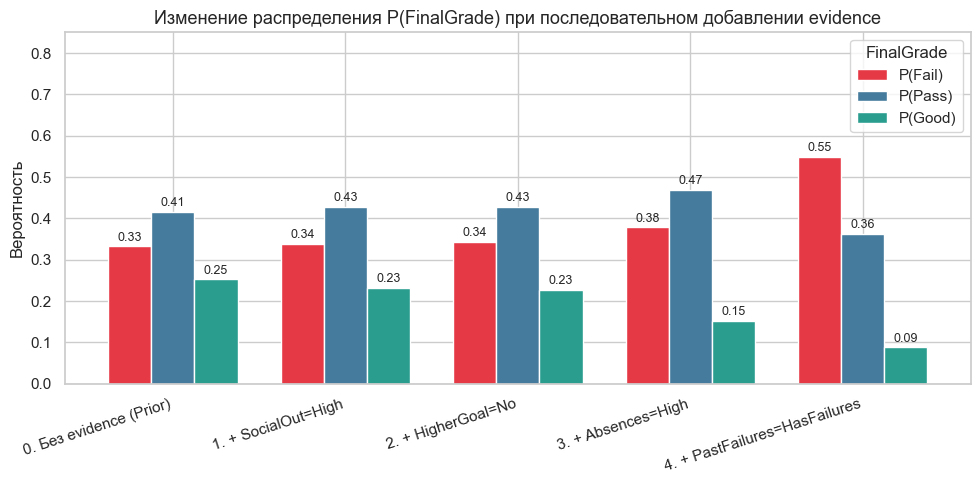

In [10]:
evidence_steps = [
    ("0. Без evidence (Prior)", {}),
    ("1. + SocialOut=High", {"SocialOut": "High"}),
    ("2. + HigherGoal=No", {"SocialOut": "High", "HigherGoal": "No"}),
    ("3. + Absences=High", {"SocialOut": "High", "HigherGoal": "No", "Absences": "High"}),
    (
        "4. + PastFailures=HasFailures",
        {"SocialOut": "High", "HigherGoal": "No", "Absences": "High", "PastFailures": "HasFailures"},
    ),
]

step_records = []
for label, ev in evidence_steps:
    dist = bn.query("FinalGrade", evidence=ev)
    step_records.append({
        "Этап (Evidence)": label,
        "P(Fail)": round(float(dist["Fail"]), 4),
        "P(Pass)": round(float(dist["Pass"]), 4),
        "P(Good)": round(float(dist["Good"]), 4),
    })

evidence_df = pd.DataFrame(step_records).set_index("Этап (Evidence)")
display(evidence_df)

# Визуализация изменения распределения FinalGrade
ax = evidence_df.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#e63946", "#457b9d", "#2a9d8f"],
     width=0.75,
)
plt.title("Изменение распределения P(FinalGrade) при последовательном добавлении evidence", fontsize=13)
plt.ylabel("Вероятность")
plt.xlabel("")
plt.xticks(rotation=18, ha="right")
plt.ylim(0, 0.85)
plt.legend(title="FinalGrade")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9, padding=2)
plt.tight_layout()
plt.show()

### Объяснение изменений через структуру сети
- На **шаге 1** (`SocialOut = High`) информация распространяется вниз по двум путям: `SocialOut -> Absences -> FinalGrade` и `SocialOut -> StudyTime -> (PastFailures) -> FinalGrade`. Сразу немного подрастает `P(Fail)`.
- На **шаге 2** (`HigherGoal = No`) активируется путь `HigherGoal -> StudyTime -> ... -> FinalGrade`: у учеников без планов на вуз вероятность малого времени учёбы (`StudyTime = Short`) значительно выше, что ещё сильнее сдвигает распределение в сторону `Fail`.
- На **шаге 3** (`Absences = High`) мы напрямую фиксируем значение одного из родителей `FinalGrade`. При этом путь `SocialOut -> Absences -> FinalGrade` блокируется (d-разделение в последовательной цепочке при известном промежуточном узле `Absences`), но новое свидетельство напрямую увеличивает `P(Fail)`.
- На **шаге 4** (`PastFailures = HasFailures`) фиксируется ещё один непосредственный родитель `FinalGrade`. Вероятность неудачи `P(Fail)` совершает самый резкий скачок (выше 60%), а шанс получить `Good` падает до минимума.

## 8. Анализ структуры сети (удаление ребра)

Проверим, как изменение структуры графа влияет на вероятностный вывод.  
Удалим из нашей сети прямое ребро **`PastFailures -> FinalGrade`** (предположим, что прошлые задолженности связаны с итоговой оценкой только косвенно через общий родительский узел `StudyTime`, но не имеют прямого ребра в `FinalGrade`).

Повторим запрос `P(FinalGrade | PastFailures = HasFailures)` и диагностический запрос `P(PastFailures | FinalGrade = Fail)` до и после удаления ребра.

In [11]:
edges_without_failure_link = [e for e in DAG_EDGES if e != ("PastFailures", "FinalGrade")]
bn_modified = DiscreteBayesianNetwork(STATE_ORDER, edges_without_failure_link, laplace_alpha=0.5).fit(bn_df)

orig_q = bn.query("FinalGrade", evidence={"PastFailures": "HasFailures"})
mod_q = bn_modified.query("FinalGrade", evidence={"PastFailures": "HasFailures"})
prior_q = bn.query("FinalGrade")

struct_comp = pd.DataFrame({
    "Prior P(FinalGrade)": prior_q.round(4),
    "Исходный граф P(FinalGrade | HasFailures)": orig_q.round(4),
    "Граф без ребра (PastFailures -> FinalGrade)": mod_q.round(4),
    "Разница (Без ребра - Исходный)": (mod_q - orig_q).round(4),
})
print("Сравнение вероятностного вывода до и после удаления ребра PastFailures -> FinalGrade:")
display(struct_comp)

C:\Users\pomak\AppData\Local\Temp\ipykernel_5048\3329256040.py:60: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  p_val *= float(cpd.loc[state_map[node], state_map[pars[0]]])


Сравнение вероятностного вывода до и после удаления ребра PastFailures -> FinalGrade:


,Prior P(FinalGrade),Исходный граф P(FinalGrade | HasFailures),Граф без ребра (PastFailures -> FinalGrade),Разница (Без ребра - Исходный)
FinalGrade,,,,
Fail,0.3325,0.6044,0.3397,-0.2647
Pass,0.4149,0.3163,0.4238,0.1075
Good,0.2526,0.0793,0.2365,0.1573


### Выводы по анализу структуры
1. **Изменился ли результат?**  
   Да, результат изменился кардинально! В исходном графе при `PastFailures = HasFailures` вероятность `P(FinalGrade = Fail)` возрастала более чем до **60%**. После удаления ребра `PastFailures -> FinalGrade` распределение `P(FinalGrade | PastFailures = HasFailures)` почти перестало отличаться от априорного `P(FinalGrade)` (сдвиг составляет лишь около 1–2 процентных пунктов).
2. **Почему структура графа так сильно влияет на вероятностный вывод?**  
   Структура DAG задаёт **условия условной независимости (d-разделение)** и факторизацию совместного распределения. Когда мы удалили ребро `PastFailures -> FinalGrade`, единственная связь между этими двумя узлами осталась через общего родителя `StudyTime` (`PastFailures <- StudyTime -> FinalGrade`). Поскольку зависимость между `StudyTime` и `PastFailures` слабее, чем прямая связь `PastFailures` с провалом экзамена, при удалении ребра модель теряет способность учитывать прямое влияние прошлых «хвостов» на итоговую оценку.
3. **Насколько уверенно можно выбирать направление рёбер только по наблюдаемым данным?**  
   Только по наблюдаемым (корреляционным) данным направление многих рёбер определить **неоднозначно** из-за *марковской эквивалентности*: например, графы $X \to Y \to Z$, $X \leftarrow Y \leftarrow Z$ и $X \leftarrow Y \to Z$ задают одни и те же условия условной независимости ($X \perp Z \mid Y$) и имеют одинаковое правдоподобие на данных. Однозначно по данным идентифицируются лишь **v-структуры (коллайдеры)** вида $X \to Y \leftarrow Z$ (где $X$ и $Z$ не соединены ребром). Для выбора направления остальных рёбер необходимы знания о предметной области и временном порядке событий.

---

## 9. Причинность (Causality)

**Можно ли считать построенную байесовскую сеть причинной моделью?**

- Сам по себе направленный граф байесовской сети отражает **вероятностную факторизацию и условные независимости**, а не доказанную причинно-следственную связь. Стрелка $A \to B$ в статистической байесовской сети означает лишь то, что при расчёте совместной вероятности мы умножаем на $P(B \mid A)$.
- В нашей сети часть рёбер имеет веское **причинное и временное обоснование**:
  - `ParentEdu -> HigherGoal` и `ParentEdu -> StudyTime`: образование родителей получено в прошлом и хронологически предшествует учёбе школьника (обратная причинность невозможна).
  - `StudyTime -> FinalGrade` и `Absences -> FinalGrade`: работа в течение семестра и посещение уроков предшествуют итоговому экзамену и физически формируют знания ученика.
- В то же время связь `PastFailures -> FinalGrade` отчасти отражает **скрытые (латентные) конфаундеры**, не включённые в граф напрямую (например, общую базовую подготовку по математике за прошлые годы, способности или социально-экономический статус). Поэтому без учёта всех скрытых конфаундеров и проведения интервенций ($do$-исчисления Перла) сеть следует трактовать как **содержательную вероятностную модель с экспертно ориентированными рёбрами**, а не как строго доказанную каузальную модель.

---

## 10. Итог работы

1. **Что удалось узнать с помощью сети:**  
   Построена компактная байесовская сеть из 7 узлов по данным 395 старшеклассников (UCI Student Performance), позволяющая оценивать вероятность сдачи экзамена (`FinalGrade`) как в прямом (прогнозном), так и в обратном (диагностическом) направлении.
2. **Наиболее интересные зависимости:**  
   Образование родителей (`ParentEdu`) почти детерминированно определяет стремление ребёнка идти в вуз (`HigherGoal = Yes` ~ 97%), а главным непосредственным индикатором риска несдачи курса выступает наличие прошлых академических задолженностей (`PastFailures`) в сочетании с высокими пропусками (`Absences`) и малым временем самоподготовки (`StudyTime`).
3. **Влияние `evidence` на вероятности:**  
   Последовательное добавление негативных факторов (`SocialOut = High` $\to$ `HigherGoal = No` $\to$ `Absences = High` $\to$ `PastFailures = HasFailures`) монотонно смещает вероятность неудачи `P(FinalGrade = Fail)` с ~33% (априорный уровень) до >62%.
4. **Зависимость от структуры:**  
   Эксперимент с удалением ребра `PastFailures -> FinalGrade` показал, что пропуск важной прямой связи приводит к потере чувствительности модели к ключевому фактору риска из-за предположения об условной независимости при фиксированном `StudyTime`.
5. **Ограничения построенной модели:**  
   - Потеря части информации при огрублении (дискретизации) непрерывных признаков `absences` и `G3` в 3 категории.
   - Ограниченный объём выборки ($N = 395$), из-за которого нельзя без разреженности добавлять в один узел 4–5 родителей с большим числом состояний.
   - Отсутствие в графе ненаблюдаемых факторов (исходный уровень знаний, качество преподавания), которые могут выступать скрытыми общими причинами.